
### **Daegu Apartment Price Prediction**

Capstone Project Module 3 - Regresi

### **Contents**

1. Business Problem Understanding
2. Data Understanding
3. Data Preprocessing
4. Modeling
5. Cara Kerja Algoritma Final Model
6. Conclusion
7. Recommendation

****

### **Business Problem Understanding**

**Context**

Apartemen menjadi salah satu jawaban atas kebutuhan hunian masyarakat modern karena lahan permukiman di perkotaan terbatas dan aktivitas bisnis yang padat. Unit apartemen biasanya ditawarkan oleh individu atau perusahaan melalui sebuah platform jual-beli, di mana penjual menentukan sendiri harga unitnya. Dataset yang digunakan berisi data apartemen di kota Daegu, Korea Selatan.

Menentukan harga yang sesuai dengan pasar tidaklah mudah bagi pemilik unit. Jika harga terlalu tinggi dibanding harga pasar, unit akan sulit terjual. Sebaliknya, jika terlalu rendah, pemilik tidak akan mendapatkan keuntungan yang maksimal. Harga sebuah apartemen dipengaruhi banyak faktor internal (misalnya luas unit, tahun bangun, fasilitas di dalam apartemen) maupun eksternal (misalnya jarak ke stasiun subway dan fasilitas di sekitarnya).

**Stakeholder**

- **Pengguna model:** pemilik unit / penjual apartemen (individu maupun perusahaan), yang menggunakan model saat **membuat listing baru, sebelum harga dipublikasikan**.
- **Penyedia model:** platform jual-beli apartemen, yang dapat menyediakan model ini sebagai fitur rekomendasi harga bagi para penjualnya.

**Problem Statement**

Penjual apartemen memiliki kebebasan penuh menentukan harga, tetapi hanya memiliki sedikit acuan untuk membandingkannya dengan unit sejenis. Akibatnya harga listing sering meleset dari harga pasar: terlalu tinggi membuat unit lama terjual, terlalu rendah membuat penjual kehilangan potensi keuntungan.

**Goals**

Membangun **model prediksi harga jual (`SalePrice`) apartemen** berdasarkan karakteristik unit dan lingkungannya, sebagai 'tool' rekomendasi harga awal bagi penjual. Target yang ingin dicapai:

- Rata-rata kesalahan prediksi (**MAPE) di bawah 20%** pada data yang belum pernah dilihat model (test set). Berdasarkan Lewis (1982), MAPE 10-20% dikategorikan *good forecasting*.
- Mengetahui **fitur apa yang paling memengaruhi harga**, dan **jenis unit apa yang prediksinya masih kurang dapat dipercaya**, sehingga penjual tahu kapan rekomendasi model bisa diandalkan.

Bagi platform, rekomendasi harga yang wajar dapat membantu penjual memasang harga yang kompetitif sehingga unit lebih cepat terjual.

**Analytic Approach**

Kita akan menganalisis pola dari fitur-fitur apartemen yang membedakan satu unit dengan unit lainnya, lalu membangun **model regresi** untuk memprediksi harga jual. Beberapa algoritma akan dibandingkan, kemudian model terbaik akan dioptimalkan dengan hyperparameter tuning.

**Metric Evaluation**

Metrik yang digunakan adalah:

- **MAPE** (*Mean Absolute Percentage Error*): rata-rata persentase kesalahan prediksi terhadap harga aktual. Ini **metrik utama** karena kesalahan Rp/Won yang sama terasa jauh berbeda untuk unit murah dan unit mahal, dan persentase mudah dipahami penjual.
- **MAE** (*Mean Absolute Error*): rata-rata selisih absolut antara prediksi dan harga aktual (dalam Won), sehingga mudah diinterpretasi sebagai "rata-rata meleset sekitar sekian Won".
- **RMSE** (*Root Mean Squared Error*): akar dari rata-rata kuadrat error. Karena error dikuadratkan, RMSE memberi bobot lebih pada kesalahan besar, yang relevan karena satu listing yang meleset jauh bisa merugikan penjual.
- **R-squared**: proporsi variasi harga yang dapat dijelaskan model, sebagai gambaran kecocokan model secara keseluruhan.

Semakin kecil nilai MAPE, MAE, dan RMSE, semakin akurat modelnya. Semakin mendekati 1 nilai R-squared, semakin baik model menjelaskan variasi data.

*Source: Lewis, C. D. (1982). Industrial and business forecasting methods: A practical guide to exponential smoothing and curve fitting.*

### **Data Understanding**

- Dataset merupakan data penjualan apartemen di kota Daegu.
- Setiap baris data merepresentasikan **satu unit apartemen** beserta karakteristik unit dan lingkungannya, serta harga jualnya.
- Target yang akan diprediksi adalah `SalePrice`. Menurut dokumentasi satuannya Won, tetapi nilainya (puluhan hingga ratusan ribu) terlihat kecil untuk harga apartemen, sehingga satuan sebenarnya kemungkinan berbeda. Ini tidak memengaruhi analisis karena metrik utama adalah MAPE (persentase); MAE dan RMSE dilaporkan dalam satuan harga pada dataset.

**Attributes Information**

| **Attribute** | **Data Type** | **Description** |
| --- | --- | --- |
| HallwayType | Object | Tipe apartemen (terraced, mixed, corridor) |
| TimeToSubway | Object | Waktu tempuh ke stasiun subway terdekat |
| SubwayStation | Object | Nama stasiun subway terdekat |
| N_FacilitiesNearBy(ETC) | Float | Jumlah fasilitas lain di sekitar |
| N_FacilitiesNearBy(PublicOffice) | Float | Jumlah fasilitas kantor publik di sekitar |
| N_SchoolNearBy(University) | Float | Jumlah universitas di sekitar |
| N_Parkinglot(Basement) | Float | Jumlah tempat parkir (basement) |
| YearBuilt | Integer | Tahun apartemen dibangun |
| N_FacilitiesInApt | Integer | Jumlah fasilitas di dalam apartemen |
| Size(sqf) | Integer | Luas apartemen (square feet). Pada dokumentasi tertulis `Size(sqft)`, tetapi nama kolom di file adalah `Size(sqf)` |
| SalePrice | Integer | Harga apartemen (Won) - **target** |

<br>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [47]:
# Load dataset
df = pd.read_csv('data_daegu_apartment.csv')
print(f'Jumlah baris: {df.shape[0]}, jumlah kolom: {df.shape[1]}')
df.head()

Jumlah baris: 4123, jumlah kolom: 11


,HallwayType,TimeToSubway,SubwayStation,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
0,terraced,0-5min,Kyungbuk_uni_hospital,0.0,3.0,2.0,1270.0,2007,10,1387,346017
1,terraced,10min~15min,Kyungbuk_uni_hospital,1.0,5.0,1.0,0.0,1986,4,914,150442
2,mixed,15min~20min,Chil-sung-market,1.0,7.0,3.0,56.0,1997,5,558,61946
3,mixed,5min~10min,Bangoge,5.0,5.0,4.0,798.0,2005,7,914,165486
4,terraced,0-5min,Sin-nam,0.0,1.0,2.0,536.0,2006,5,1743,311504


#### **Exploratory Data Analysis**


**Distribution of SalePrice**

Skewness SalePrice: 0.45


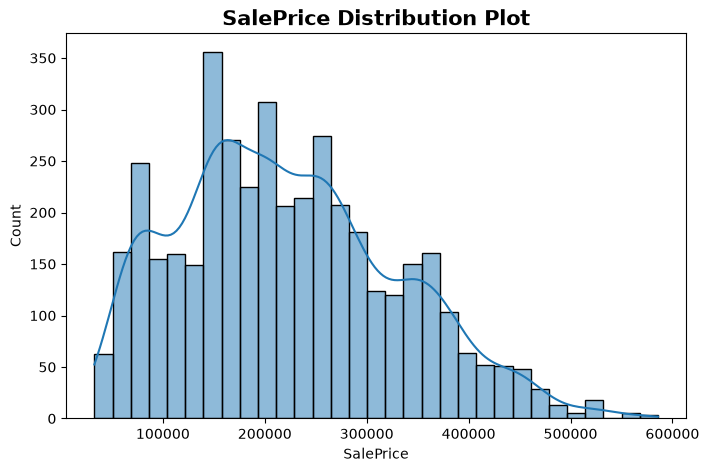

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['SalePrice'], kde=True)
plt.title('SalePrice Distribution Plot', size=15, weight='bold')
print('Skewness SalePrice:', round(df['SalePrice'].skew(), 2))

Distribusi `SalePrice` hanya sedikit miring ke kanan (skewness sekitar 0,45), jauh lebih ringan dibanding data harga pada umumnya yang sangat *right-skewed*. Karena itu **transformasi logaritmik pada target tidak diperlukan** pada project ini.

**Harga berdasarkan tipe apartemen, luas, dan stasiun terdekat**

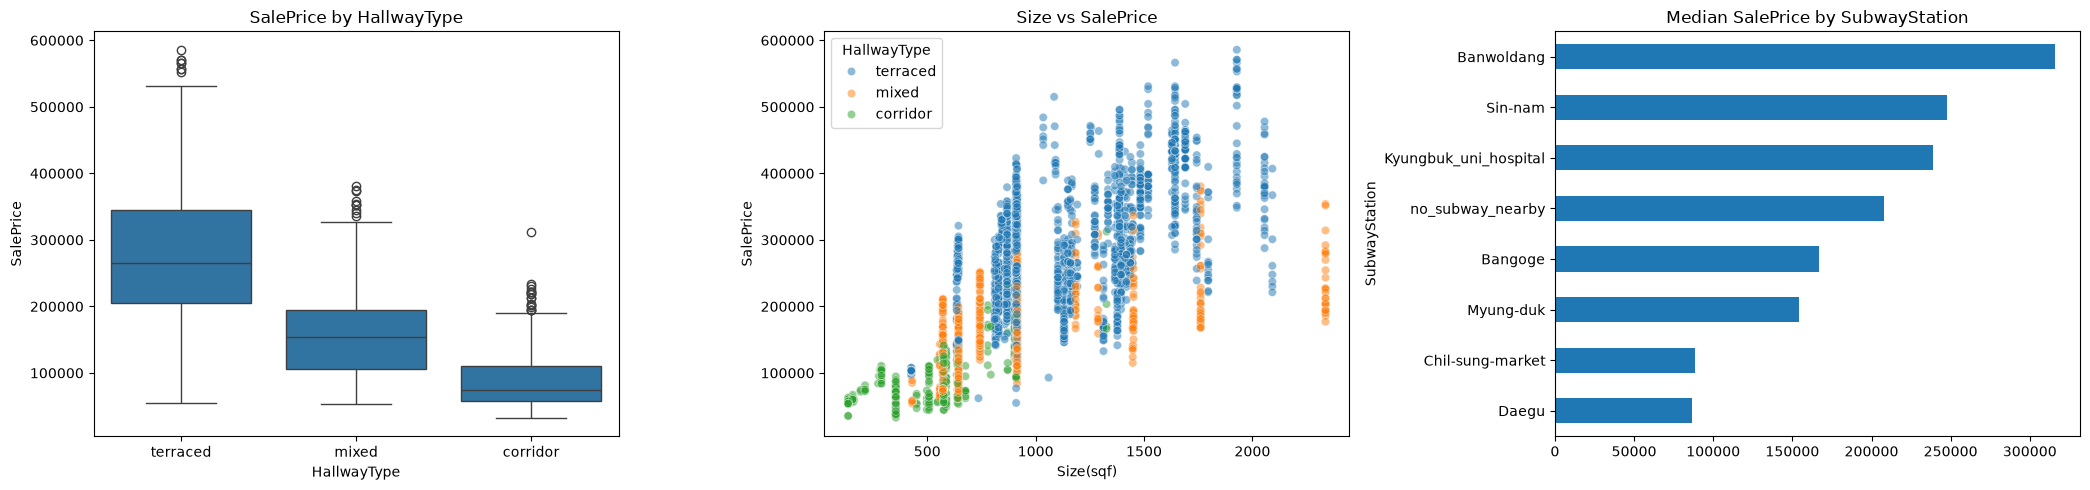

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# Harga berdasarkan tipe apartemen
sns.boxplot(x='HallwayType', y='SalePrice', data=df, ax=axes[0])
axes[0].set_title('SalePrice by HallwayType')

# Hubungan luas unit dengan harga
sns.scatterplot(x='Size(sqf)', y='SalePrice', hue='HallwayType', data=df, alpha=0.5, ax=axes[1])
axes[1].set_title('Size vs SalePrice')

# Median harga berdasarkan stasiun terdekat
df.groupby('SubwayStation')['SalePrice'].median().sort_values().plot(kind='barh', ax=axes[2])
axes[2].set_title('Median SalePrice by SubwayStation')
plt.tight_layout()

Beberapa temuan awal:
- **Tipe apartemen** sangat memengaruhi harga: median harga tipe *terraced* jauh lebih tinggi dibanding *mixed*, dan *corridor* paling rendah.
- **Luas unit** berhubungan positif dengan harga, tetapi pada luas yang sama harganya bisa sangat bervariasi (pada plot, unit sekitar 900 sqf berkisar dari puluhan ribu hingga lebih dari 400 ribu). Artinya luas saja tidak cukup; tipe apartemen dan lokasi ikut menentukan. Unit besar bertipe *mixed* (sekitar 2.300 sqf) bahkan lebih murah dibanding sebagian unit *terraced* yang jauh lebih kecil.
- **Stasiun terdekat** menunjukkan perbedaan median harga yang jelas: Banwoldang paling tinggi, sedangkan Daegu dan Chil-sung-market paling rendah.

### **Data Preprocessing**

- Mengecek missing value, data duplikat, dan nilai yang tidak masuk akal.
- Mengecek outlier dan memutuskan treatment-nya dengan mempertimbangkan domain knowledge.
- Menyiapkan encoding untuk fitur kategorikal dan scaling untuk fitur numerikal.
- Menentukan fitur yang akan digunakan (feature selection).

Proses preprocessing dilakukan pada hasil duplikasi dataframe agar data asli tetap utuh.

In [50]:
df_model = df.copy()

In [51]:
listItem = []

for col in df_model.columns:
    listItem.append([col, df_model[col].dtype, df_model[col].isna().sum(),
                     round((df_model[col].isna().sum()/len(df_model[col]))*100, 2),
                     df_model[col].nunique(), list(df_model[col].drop_duplicates().head(2).values)])

df_model_desc = pd.DataFrame(columns=['dataFeatures', 'dataType', 'null', 'nullPct', 'unique', 'uniqueSample'],
                             data=listItem)
df_model_desc

,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,HallwayType,str,0,0.0,3,"[terraced, mixed]"
1,TimeToSubway,str,0,0.0,5,"[0-5min, 10min~15min]"
2,SubwayStation,str,0,0.0,8,"[Kyungbuk_uni_hospital, Chil-sung-market]"
3,N_FacilitiesNearBy(ETC),float64,0,0.0,4,"[0.0, 1.0]"
4,N_FacilitiesNearBy(PublicOffice),float64,0,0.0,8,"[3.0, 5.0]"
5,N_SchoolNearBy(University),float64,0,0.0,6,"[2.0, 1.0]"
6,N_Parkinglot(Basement),float64,0,0.0,20,"[1270.0, 0.0]"
7,YearBuilt,int64,0,0.0,16,"[2007, 1986]"
8,N_FacilitiesInApt,int64,0,0.0,9,"[10, 4]"
9,Size(sqf),int64,0,0.0,89,"[1387, 914]"


Tidak ada missing value pada seluruh fitur, sehingga tidak diperlukan imputasi. Tipe data juga sudah sesuai: 3 fitur kategorikal (object) dan sisanya numerikal.

**Data Duplikat**

Dataset ini tidak memiliki kolom ID, sehingga tidak bisa langsung membedakan apakah dua baris yang identik adalah unit yang berbeda atau data yang tercatat ganda.

In [ ]:
n_dup = df_model.duplicated().sum()
print(f'Jumlah baris duplikat: {n_dup} ({n_dup/len(df_model)*100:.1f}% dari total data)')

Jumlah baris duplikat: 1422 (34.5% dari total data)


Terdapat **1.422 baris duplikat (34,5% data)**. Baris duplikat di sini identik pada **seluruh kolom, termasuk harga**. Ada dua kemungkinan: (1) unit yang berbeda di kompleks yang sama dengan karakteristik dan harga yang kebetulan persis sama, atau (2) data yang tercatat ganda. Karena tidak ada ID, jadi tidak bisa memastikan mana yang benar. Untuk memutuskannya, dapat dilihat dampaknya terhadap evaluasi model.

In [53]:
# Simulasi: jika duplikat tidak dibuang, berapa persen baris test yang punya 'kembaran' persis di data train?
from sklearn.model_selection import train_test_split

sim_train, sim_test = train_test_split(df_model, test_size=0.2, random_state=1)
merged = sim_test.merge(sim_train.drop_duplicates(), how='left', indicator=True)
print(f"Baris test yang identik dengan baris di train: {(merged['_merge']=='both').mean()*100:.1f}%")

Baris test yang identik dengan baris di train: 46.1%


Hasil simulasi menunjukkan bahwa jika duplikat dibiarkan, sekitar 46% baris di test set memiliki 'kembaran' persis di train set. Model akan terlihat jauh lebih akurat dari kenyataannya karena sebagian test set sebenarnya sudah 'dihafal' model (*data leakage*).

Oleh karena itu, data duplikat di drop agar evaluasi model lebih baik, dengan konsekuensi jumlah data menyusut menjadi 2.701 baris. Asumsi yang dipakai: baris identik tidak membawa informasi baru bagi model. Jika ternyata baris tersebut adalah unit berbeda yang valid, kehilangan sebagian data, tetapi itu trade-off yang lebih aman dibanding skor yang menyesatkan.

In [ ]:
df_model = df_model.drop_duplicates().reset_index(drop=True)
print('Ukuran data setelah drop duplikat:', df_model.shape)

Ukuran data setelah drop duplikat: (2701, 11)


**Nilai yang Tidak Masuk Akal**

Cek statistika deskriptif untuk memastikan tidak ada nilai yang tidak masuk akal (misalnya harga atau luas yang bernilai 0 atau negatif).

In [ ]:
num_features = [feature for feature in df_model.columns if df_model[feature].dtypes != 'object']
df_model[num_features].describe()

,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
count,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000
mean,1.890411,4.027027,2.680489,533.746390,2002.358386,5.713439,984.028878,229511.365790
std,2.153168,1.887486,1.504470,418.224859,9.151949,2.386552,391.982619,105079.891321
min,0.000000,0.000000,0.000000,0.000000,1978.000000,1.000000,135.000000,32743.000000
25%,0.000000,3.000000,2.000000,181.000000,1993.000000,4.000000,743.000000,153539.000000
50%,1.000000,4.000000,2.000000,536.000000,2006.000000,5.000000,910.000000,221238.000000
75%,5.000000,5.000000,4.000000,798.000000,2007.000000,7.000000,1167.000000,300884.000000
max,5.000000,7.000000,5.000000,1321.000000,2015.000000,10.000000,2337.000000,585840.000000


In [56]:
# Cek nilai <= 0 pada harga dan luas unit
print((df_model[['SalePrice', 'Size(sqf)']] <= 0).sum())

SalePrice    0
Size(sqf)    0
dtype: int64


Tidak ada harga atau luas unit yang bernilai 0 atau negatif, dan rentang nilai pada fitur lain masuk akal. Harga berkisar dari 32.743 hingga 585.840. Rentang ini penting karena menjadi batas data yang bisa diprediksi model dengan baik.

**Fitur Kategorikal**

Untuk menentukan teknik encoding, cek fitur-fitur kategorikal.

In [57]:
# Isi fitur kategorikal
for col in ['HallwayType', 'TimeToSubway', 'SubwayStation']:
    print(df_model[col].value_counts(), '\n')

HallwayType
terraced    1667
mixed        698
corridor     336
Name: count, dtype: int64 

TimeToSubway
0-5min                1248
5min~10min             501
10min~15min            434
15min~20min            418
no_bus_stop_nearby     100
Name: count, dtype: int64 

SubwayStation
Myung-duk                709
Kyungbuk_uni_hospital    692
Sin-nam                  380
Banwoldang               333
Bangoge                  280
no_subway_nearby         188
Chil-sung-market          65
Daegu                     54
Name: count, dtype: int64 



In [58]:
# Hubungan TimeToSubway dengan SubwayStation, dan median harga tiap kategori TimeToSubway
print(pd.crosstab(df_model['TimeToSubway'], df_model['SubwayStation']).to_string())
print()
print(df_model.groupby('TimeToSubway')['SalePrice'].median().sort_values())

SubwayStation       Bangoge  Banwoldang  Chil-sung-market  Daegu  Kyungbuk_uni_hospital  Myung-duk  Sin-nam  no_subway_nearby
TimeToSubway                                                                                                                 
0-5min                    0         301                 0      0                    402        212      333                 0
10min~15min               0           0                 0      0                    290        144        0                 0
15min~20min               0           0                65      0                      0        353        0                 0
5min~10min              280          32                 0     54                      0          0       47                88
no_bus_stop_nearby        0           0                 0      0                      0          0        0               100

TimeToSubway
15min~20min           148672.0
5min~10min            165486.0
10min~15min           170796.0
no_bus_stop

Temuan dan keputusan encoding:
- `HallwayType` (3 kategori) dan `SubwayStation` (8 kategori) adalah kategori nominal tanpa urutan, sehingga di-*one hot encode*.
- `TimeToSubway` sekilas tampak ordinal (0-5 menit sampai 15-20 menit), tetapi ada kategori `no_bus_stop_nearby` yang tidak punya posisi urutan yang jelas, dan median harganya tidak monoton (misalnya `5min~10min` lebih murah dari `10min~15min`, sementara `no_bus_stop_nearby` berada di tengah). Jika dipaksa menjadi angka berurutan, menambahkan asumsi yang tidak didukung data. Maka `TimeToSubway` juga di-**one hot encode**.
- Tabel crosstab menunjukkan bahwa `TimeToSubway` hampir ditentukan oleh `SubwayStation` (tiap stasiun hanya memiliki 1-3 nilai waktu tempuh), sehingga informasi kedua fitur ini saling tumpang tindih.
- Ada sedikit inkonsistensi label: 88 unit bertanda `no_subway_nearby` tetapi `TimeToSubway`-nya `5min~10min`. Tanpa penjelasan dari sumber data, biarkan apa adanya.

**Outliers Detection**

Banyaknya outlier dapat memengaruhi hasil pemodelan, tetapi menghapus outlier begitu saja belum tentu tepat. menggunakan metode IQR untuk mendeteksinya, lalu keputusan treatment diambil dengan mempertimbangkan domain knowledge.

In [ ]:
def find_anomalies(data):
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    limit_bawah = q1 - iqr*1.5
    limit_atas = q3 + iqr*1.5
    n_out = ((data < limit_bawah) | (data > limit_atas)).sum()
    print(f'{data.name}: IQR={iqr:.0f}, limit_bawah={limit_bawah:.0f}, limit_atas={limit_atas:.0f}, '
          f'jumlah outlier={n_out} ({n_out/len(data)*100:.1f}%)')

for col in ['SalePrice', 'Size(sqf)', 'N_Parkinglot(Basement)']:
    find_anomalies(df_model[col])

SalePrice: IQR=147345, limit_bawah=-67478, limit_atas=521902, jumlah outlier=17 (0.6%)
Size(sqf): IQR=424, limit_bawah=107, limit_atas=1803, jumlah outlier=84 (3.1%)
N_Parkinglot(Basement): IQR=617, limit_bawah=-744, limit_atas=1724, jumlah outlier=0 (0.0%)


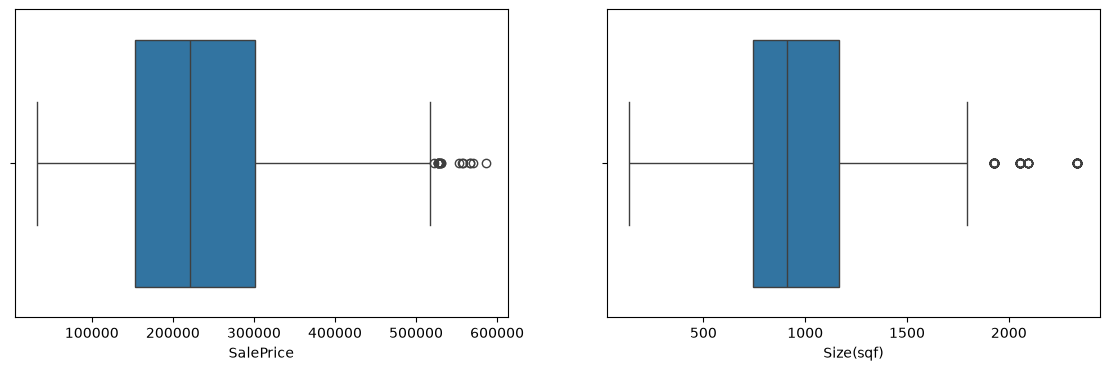

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df_model['SalePrice'], ax=axes[0])
sns.boxplot(x=df_model['Size(sqf)'], ax=axes[1]);

Hasilnya, `SalePrice` hanya memiliki 17 outlier (0,6%) dan `Size(sqf)` 84 outlier (3,1%), sedangkan `N_Parkinglot(Basement)` tidak ada.

Berbeda dengan data harga yang biasanya memiliki outlier ekstrem, nilai-nilai ini **masih masuk akal secara domain**: outlier harga adalah unit-unit termahal, dan outlier luas adalah unit berukuran besar (hingga sekitar 2.300 sqf) yang memang ada di pasar. Karena jumlahnya kecil, nilainya valid, dan model berbasis pohon tidak sensitif terhadap outlier, **outlier tidak didrop**.

Konsekuensinya, model hanya dapat dipercaya pada rentang yang dilihat saat training (harga 32.743 sampai 585.840 dan luas hingga sekitar 2.300 sqf).

**Data Correlation**

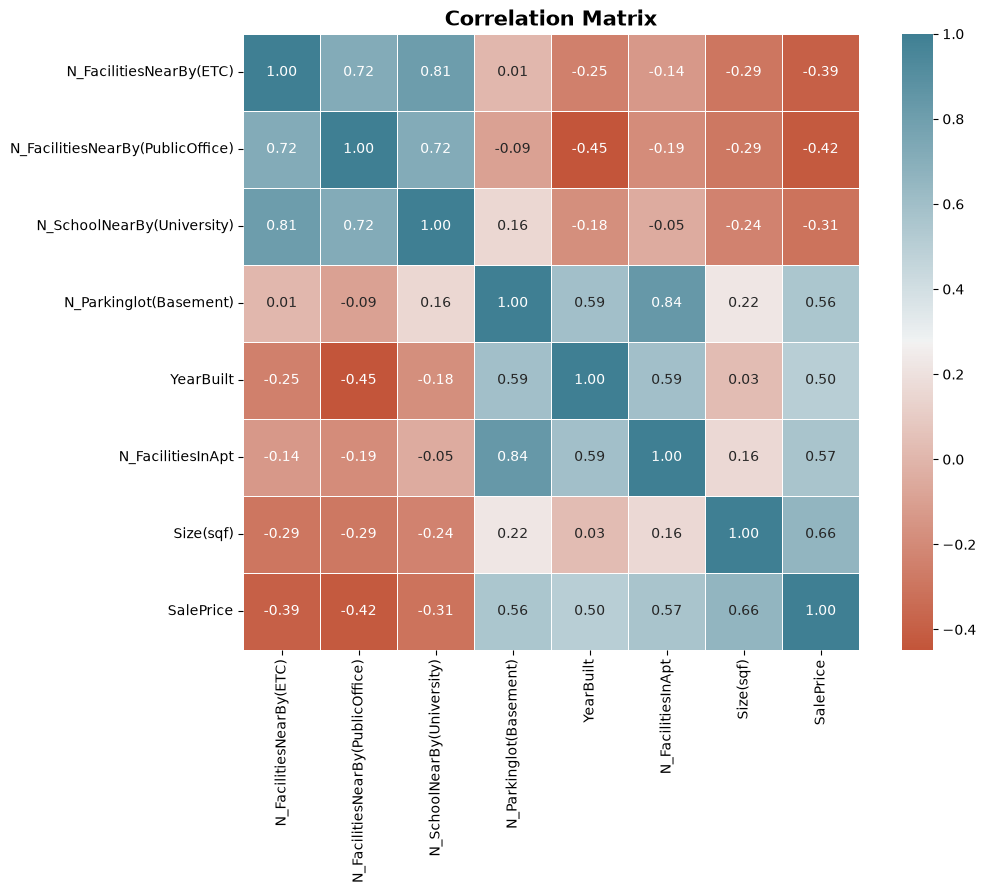

In [ ]:
plt.figure(figsize=(11, 8))
palette = sns.diverging_palette(20, 220, n=256)
corr = df_model.corr(method='pearson', numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap=palette, square=True, linewidths=.5)
plt.title('Correlation Matrix', size=15, weight='bold');

- `Size(sqf)` memiliki korelasi paling kuat dengan harga (sekitar 0,66), diikuti `N_FacilitiesInApt` (0,57), `N_Parkinglot(Basement)` (0,56), dan `YearBuilt` (0,50).
- Fitur jumlah fasilitas/kampus di sekitar (`ETC`, `PublicOffice`, `University`) berkorelasi **negatif** dengan harga (sekitar -0,31 sampai -0,42). Secara intuitif ini tampak janggal, kemungkinan karena fasilitas tersebut berkaitan dengan area tertentu yang karakter unitnya berbeda. Ini korelasi, bukan hubungan sebab-akibat.
- Ketiga fitur tersebut juga saling berkorelasi tinggi (misalnya `ETC` dengan `University` sekitar 0,81 dan dengan `PublicOffice` sekitar 0,72), sehingga ada multikolinearitas. Ini bermasalah bagi Linear Regression (koefisien tidak stabil), tetapi relatif tidak masalah bagi model berbasis pohon.

**Feature Selection dan Feature Engineering**

- **Tidak ada fitur yang di-drop berdasarkan domain knowledge.** Seluruh fitur adalah karakteristik unit dan lingkungannya yang sudah diketahui penjual *sebelum* unit dijual, sehingga relevan untuk rekomendasi harga dan tidak ada fitur yang 'membocorkan' harga (tidak ada *data leakage* dari fitur).
- **Encoding:** `HallwayType`, `TimeToSubway`, dan `SubwayStation` di-*one hot encode* (alasan pada bagian fitur kategorikal). `handle_unknown='ignore'` dipakai agar model tidak error bila muncul kategori baru saat digunakan.
- **Scaling:** fitur numerikal di-*standardize* (`StandardScaler`). Ini penting untuk Linear Regression dan KNN (berbasis jarak), dan tidak merugikan model pohon.
- **Transformasi target:** tidak diperlukan karena skewness `SalePrice` rendah.
- **Feature engineering tambahan** (misalnya usia bangunan dari `YearBuilt`) tidak dilakukan karena bagi model pohon hanya mengubah skala yang sama dan tidak menambah informasi.
- Kontribusi tiap kelompok fitur akan diuji dengan eksperimen *feature selection* pada tahap modeling, hanya menggunakan train set.

In [ ]:
X = df_model.drop(columns='SalePrice')
y = df_model['SalePrice']

cat_cols = ['HallwayType', 'TimeToSubway', 'SubwayStation']
num_cols = [col for col in X.columns if col not in cat_cols]
print('Fitur kategorikal:', cat_cols)
print('Fitur numerikal  :', num_cols)

Fitur kategorikal: ['HallwayType', 'TimeToSubway', 'SubwayStation']
Fitur numerikal  : ['N_FacilitiesNearBy(ETC)', 'N_FacilitiesNearBy(PublicOffice)', 'N_SchoolNearBy(University)', 'N_Parkinglot(Basement)', 'YearBuilt', 'N_FacilitiesInApt', 'Size(sqf)']


In [63]:
# Transformer: One Hot Encoding untuk fitur kategorikal, Standard Scaling untuk fitur numerikal
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('scaler', StandardScaler(), num_cols)
])

### **Modeling**

1. Membagi data menjadi train dan test set.
2. Membandingkan beberapa algoritma (benchmark) dengan cross validation pada train set.
3. Memilih model terbaik, lalu melakukan hyperparameter tuning.
4. Mengevaluasi model akhir pada test set, termasuk menganalisis di mana model akurat dan di mana tidak.

Semua langkah preprocessing berada di dalam satu `Pipeline` bersama model, sehingga scaling dan encoding hanya 'belajar' dari data train (tidak ada *data leakage* dari test set) dan pipeline yang sama bisa disimpan untuk deployment.

**Train and Test Splitting**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1)

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (2160, 10) | Test: (541, 10)


**Memilih Benchmark Model**

Kita membandingkan 5 algoritma dengan 5-fold cross validation pada train set: Linear Regression, KNN, Decision Tree, Random Forest, dan Gradient Boosting. Pemilihan awal dilakukan dengan cross validation (bukan test set) agar test set tetap 'bersih' untuk evaluasi akhir.

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# Kandidat algoritma
models = {
    'Linear Regression': LinearRegression(),
    'KNN Regressor': KNeighborsRegressor(),
    'DecisionTree Regressor': DecisionTreeRegressor(random_state=1),
    'RandomForest Regressor': RandomForestRegressor(random_state=1),
    'GradientBoosting Regressor': GradientBoostingRegressor(random_state=1)
}

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'mape': 'neg_mean_absolute_percentage_error',
    'r2': 'r2'
}

crossval = KFold(n_splits=5, shuffle=True, random_state=1)

hasil = []
for nama, model in models.items():
    estimator = Pipeline([
        ('preprocessing', transformer),
        ('model', model)
    ])
    cv = cross_validate(estimator, X_train, y_train, cv=crossval, scoring=scoring)
    hasil.append({
        'Model': nama,
        'Mean_RMSE': -cv['test_rmse'].mean(), 'Std_RMSE': cv['test_rmse'].std(),
        'Mean_MAE': -cv['test_mae'].mean(), 'Std_MAE': cv['test_mae'].std(),
        'Mean_MAPE': -cv['test_mape'].mean(), 'Std_MAPE': cv['test_mape'].std(),
        'Mean_R2': cv['test_r2'].mean()
    })

cv_result = pd.DataFrame(hasil).set_index('Model')
cv_result.round(3)

,Mean_RMSE,Std_RMSE,Mean_MAE,Std_MAE,Mean_MAPE,Std_MAPE,Mean_R2
Model,,,,,,,
Linear Regression,51866.109,1126.741,41890.481,1386.977,0.217,0.008,0.754
KNN Regressor,49098.674,548.375,38442.573,648.051,0.192,0.009,0.779
DecisionTree Regressor,46798.992,817.211,37350.032,545.336,0.191,0.006,0.800
RandomForest Regressor,46625.132,772.444,37246.664,478.832,0.190,0.006,0.801
GradientBoosting Regressor,46381.450,716.702,37231.392,873.092,0.190,0.008,0.803


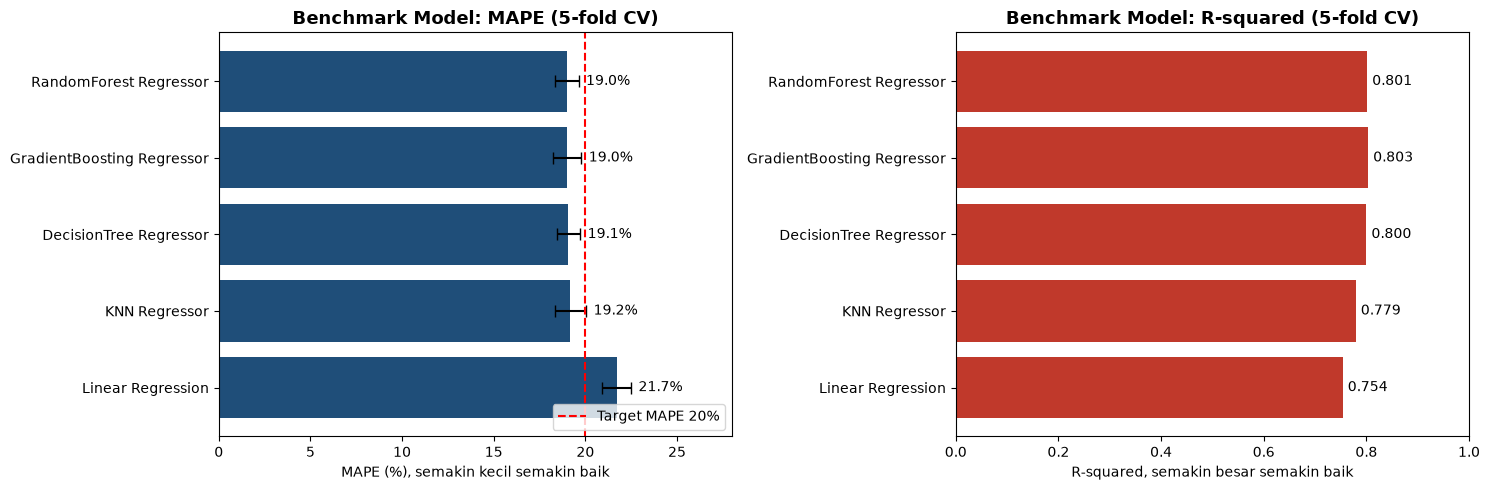

In [ ]:
urut = cv_result.sort_values('Mean_MAPE')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(urut.index, urut['Mean_MAPE']*100, xerr=urut['Std_MAPE']*100, color='#1f4e79', capsize=4)
axes[0].axvline(20, color='red', linestyle='--', label='Target MAPE 20%')
for i, (v, sd) in enumerate(zip(urut['Mean_MAPE']*100, urut['Std_MAPE']*100)):
    axes[0].text(v + sd + 0.4, i, f'{v:.1f}%', va='center')
axes[0].set_xlim(0, 28)
axes[0].invert_yaxis()
axes[0].set_xlabel('MAPE (%), semakin kecil semakin baik')
axes[0].set_title('Benchmark Model: MAPE (5-fold CV)', size=13, weight='bold')
axes[0].legend(loc='lower right')

axes[1].barh(urut.index, urut['Mean_R2'], color='#c0392b')
for i, v in enumerate(urut['Mean_R2']):
    axes[1].text(v + 0.01, i, f'{v:.3f}', va='center')
axes[1].set_xlim(0, 1)
axes[1].invert_yaxis()
axes[1].set_xlabel('R-squared, semakin besar semakin baik')
axes[1].set_title('Benchmark Model: R-squared (5-fold CV)', size=13, weight='bold')
plt.tight_layout();

- **Linear Regression** paling lemah (R² sekitar 0,75 dan MAPE sekitar 21,7%), yang menunjukkan hubungan antara fitur dan harga tidak sepenuhnya linear.
- **Decision Tree, Random Forest, dan Gradient Boosting** hampir identik (MAPE sekitar 19%, R² sekitar 0,80). Selisih antar ketiganya lebih kecil dari standar deviasi antar fold (sekitar 0,6-0,8 poin persentase MAPE), jadi tidak ada pemenang yang benar-benar jelas. Gradient Boosting sedikit terbaik pada RMSE dan R².
- RMSE (sekitar 46-52 ribu) lebih tinggi dari MAE (sekitar 37-42 ribu) pada semua model karena RMSE memberi bobot lebih pada error yang besar. Artinya ada beberapa prediksi yang meleset cukup jauh.

**Feature Selection Check**

Dari analisis korelasi, beberapa fitur tampak tumpang tindih (`TimeToSubway` dengan `SubwayStation`, serta tiga fitur jumlah fasilitas/kampus sekitar).  Menguji apakah fitur-fitur tersebut benar-benar dibutuhkan dengan melatih model **tanpa** kelompok fitur tertentu, lalu membandingkan skor cross validation-nya dengan model yang memakai semua fitur. Eksperimen hanya memakai train set dan Gradient Boosting dengan parameter default.

In [67]:
nearby_cols = ['N_FacilitiesNearBy(ETC)', 'N_FacilitiesNearBy(PublicOffice)', 'N_SchoolNearBy(University)']

skenario = {
    'Semua fitur': [],
    'Tanpa SubwayStation': ['SubwayStation'],
    'Tanpa TimeToSubway': ['TimeToSubway'],
    'Tanpa 3 fitur fasilitas/kampus sekitar': nearby_cols,
    'Tanpa SubwayStation, TimeToSubway & 3 fitur sekitar': ['SubwayStation', 'TimeToSubway'] + nearby_cols,
    'Tanpa YearBuilt': ['YearBuilt'],
    'Tanpa Size(sqf)': ['Size(sqf)']
}

hasil_fs = []
for nama, drop_cols in skenario.items():
    X_sub = X_train.drop(columns=drop_cols)
    cat_sub = [c for c in cat_cols if c in X_sub.columns]
    num_sub = [c for c in X_sub.columns if c not in cat_sub]
    tf = ColumnTransformer([
        ('onehot', OneHotEncoder(handle_unknown='ignore'), cat_sub),
        ('scaler', StandardScaler(), num_sub)
    ])
    pipe = Pipeline([('preprocessing', tf), ('model', GradientBoostingRegressor(random_state=1))])
    cv = cross_validate(pipe, X_sub, y_train, cv=crossval, scoring=scoring)
    hasil_fs.append({'Skenario': nama, 'Jumlah fitur': X_sub.shape[1],
                     'MAPE': -cv['test_mape'].mean(), 'MAE': -cv['test_mae'].mean(), 'R2': cv['test_r2'].mean()})

pd.DataFrame(hasil_fs).set_index('Skenario').round(4)

,Jumlah fitur,MAPE,MAE,R2
Skenario,,,,
Semua fitur,10,0.1901,37231.3924,0.8033
Tanpa SubwayStation,9,0.1901,37232.9830,0.8029
Tanpa TimeToSubway,9,0.1899,37197.8170,0.8034
Tanpa 3 fitur fasilitas/kampus sekitar,7,0.1898,37252.0572,0.8033
"Tanpa SubwayStation, TimeToSubway & 3 fitur sekitar",5,0.1899,37278.5422,0.8031
Tanpa YearBuilt,9,0.1983,38048.8747,0.7893
Tanpa Size(sqf),9,0.2459,47107.0405,0.6529


Hasilnya:
- Membuang `SubwayStation`, `TimeToSubway`, tiga fitur fasilitas/kampus sekitar, atau **kelimanya sekaligus** hampir tidak mengubah skor (MAPE tetap sekitar 19,0% dan R² sekitar 0,803). Model dengan hanya 5 fitur (`HallwayType`, `N_Parkinglot(Basement)`, `YearBuilt`, `N_FacilitiesInApt`, `Size(sqf)`) sama baiknya dengan model 10 fitur.
- Sebaliknya, membuang `YearBuilt` menurunkan performa (MAPE sekitar 19,8%) dan membuang `Size(sqf)` menurunkannya jauh (MAPE sekitar 24,6%, R² sekitar 0,65).

**Keputusan:** kelima fitur lokasi/lingkungan terbukti redundan pada data ini, tetapi **seluruh fitur tetap dipertahankan** karena (1) tidak merugikan performa, dan (2) validasi dengan pembagian acak tidak dapat menguji apakah fitur lokasi berguna untuk kompleks apartemen yang benar-benar baru. Jika form input bagi penjual perlu dipersingkat, model 5 fitur adalah alternatif yang layak.


**Prediksi pada test set**
- Menggunakan dua benchmark model terbaik, sebelum hyperparameter tuning.

In [ ]:
# Fungsi untuk menghitung metrik pada data test
def hitung_metrik(y_true, y_pred):
    return {
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    }

top_models = {
    'GradientBoosting': GradientBoostingRegressor(random_state=1),
    'RandomForest': RandomForestRegressor(random_state=1)
}

skor = {}
for nama, model in top_models.items():
    pipe = Pipeline([('preprocessing', transformer), ('model', model)])
    pipe.fit(X_train, y_train)
    skor[nama] = hitung_metrik(y_test, pipe.predict(X_test))

score_before_tuning = pd.DataFrame(skor).T
score_before_tuning.round(3)

,RMSE,MAE,MAPE,R2
GradientBoosting,46587.040,38228.425,0.195,0.804
RandomForest,47131.598,38295.999,0.194,0.799


Pada test set, Gradient Boosting dan Random Forest memberi hasil yang hampir sama (MAPE 19,5% vs 19,4%, R² 0,804 vs 0,799). Gradient Boosting sedikit lebih baik pada RMSE (46.587 vs 47.132). Keduanya sudah berada di bawah target MAPE 20% bahkan sebelum tuning.

**Hyperparameter Tuning**

Gradient Boosting dipilih untuk di-tuning karena RMSE dan R²-nya sedikit terbaik pada cross validation maupun test set (meskipun selisihnya dengan Random Forest sangat kecil). Tuning dilakukan dengan `RandomizedSearchCV` (40 kombinasi, 5-fold CV) dengan **MAPE sebagai metrik yang dioptimalkan**, karena itu metrik utama project ini. Arti tiap hyperparameter dijelaskan pada komentar kode dan pada bagian 'Cara Kerja Algoritma'.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparameter space Gradient Boosting
hyperparam_space = {
    'model__n_estimators': np.arange(100, 501, 50),      
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],  
    'model__max_depth': [2, 3, 4, 5, 6],                   
    'model__min_samples_leaf': [1, 3, 5, 10, 20],          
    'model__max_features': [0.5, 0.7, 1.0]                 
}

estimator_gb = Pipeline([
    ('preprocessing', transformer),
    ('model', GradientBoostingRegressor(random_state=1))
])

random_gb = RandomizedSearchCV(
    estimator_gb,
    param_distributions=hyperparam_space,
    n_iter=40,
    cv=crossval,
    scoring=scoring,
    refit='mape',          
    n_jobs=-1,
    random_state=1
)

random_gb.fit(X_train, y_train)

print('Best CV MAPE:', round(-random_gb.best_score_, 4))
print('Best params :', random_gb.best_params_)

Best CV MAPE: 0.1891
Best params : {'model__subsample': 1.0, 'model__n_estimators': np.int64(450), 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 4, 'model__learning_rate': 0.03}


In [70]:
# Lima kombinasi hyperparameter terbaik berdasarkan MAPE
cols = ['mean_test_mape', 'mean_test_mae', 'mean_test_rmse', 'mean_test_r2', 'param_model__n_estimators',
        'param_model__learning_rate', 'param_model__max_depth']
tuning_result = pd.DataFrame(random_gb.cv_results_).sort_values('rank_test_mape')[cols].head()
tuning_result

,mean_test_mape,mean_test_mae,mean_test_rmse,mean_test_r2,param_model__n_estimators,param_model__learning_rate,param_model__max_depth
13,-0.189060,-37096.396151,-46407.852843,0.803227,450,0.03,4
14,-0.189173,-37161.756651,-46529.491348,0.802262,500,0.10,4
25,-0.189308,-37166.329488,-46493.866976,0.802469,400,0.20,3
32,-0.189479,-37107.280808,-46358.313645,0.803546,150,0.10,3
12,-0.189505,-37167.998897,-46444.996445,0.802898,350,0.05,4


**Predict to Test Set with the Tuned Model**

In [ ]:
final_model = random_gb.best_estimator_
y_pred = final_model.predict(X_test)

score_after_tuning = pd.DataFrame({'GradientBoosting (tuned)': hitung_metrik(y_test, y_pred)}).T
score_after_tuning.round(3)

,RMSE,MAE,MAPE,R2
GradientBoosting (tuned),46790.736,38092.288,0.194,0.802


**Performance Comparison**

Perbandingan performa Gradient Boosting sebelum dan sesudah hyperparameter tuning pada test set.

In [72]:
perbandingan = pd.concat([score_before_tuning.loc[['GradientBoosting']].rename(index={'GradientBoosting': 'Sebelum tuning'}),
                          score_after_tuning.rename(index={'GradientBoosting (tuned)': 'Sesudah tuning'})])
perbandingan.round(3)

,RMSE,MAE,MAPE,R2
Sebelum tuning,46587.040,38228.425,0.195,0.804
Sesudah tuning,46790.736,38092.288,0.194,0.802


Hyperparameter tuning **hampir tidak mengubah performa**: MAPE 19,5% menjadi 19,4%, MAE turun sedikit (38.228 menjadi 38.092), sementara RMSE justru naik sedikit (46.587 menjadi 46.791) dan R² praktis sama (0,804 vs 0,802). Pada cross validation pun MAPE terbaik hasil tuning (sekitar 18,9%) hanya sedikit di bawah model default (sekitar 19,0%).

Ini informasi penting: hyperparameter default sudah mendekati batas kemampuan model, sehingga **batas akurasi lebih ditentukan oleh informasi yang tersedia pada fitur, bukan oleh algoritma atau tuning**. Tetap memakai model hasil tuning sebagai model final karena skor cross validation-nya yang terbaik, tetapi perbaikan berikutnya sebaiknya difokuskan pada data.

**Actual vs Prediction**

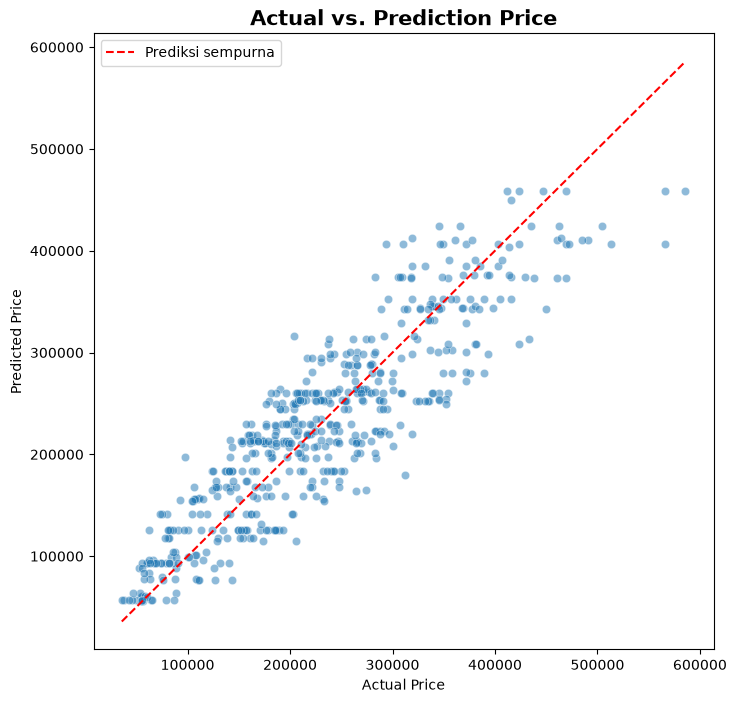

In [73]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
batas = [y_test.min(), y_test.max()]
plt.plot(batas, batas, color='red', linestyle='--', label='Prediksi sempurna')
plt.title('Actual vs. Prediction Price', size=15, weight='bold')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend();

Titik-titik secara umum mengikuti garis diagonal, artinya model menangkap pola utama harga. Namun ada dua pola yang terlihat:
1. Pada unit termahal (harga aktual di atas sekitar 450 ribu), model cenderung **meremehkan** (*underestimate*) harga, prediksinya seolah 'tertahan' di kisaran 410-460 ribu.
2. Pada unit dengan harga aktual rendah, prediksi cenderung sedikit lebih tinggi (*overestimate*).

Pola 'berundak' pada prediksi wajar karena model berbasis pohon menghasilkan nilai prediksi diskrit, dan banyak unit di kompleks yang sama memiliki karakteristik serupa.

**Error Analysis: Kapan Model Dapat Dipercaya?**

Metrik keseluruhan hanya memberi rata-rata. Untuk mengetahui di data seperti apa model akurat dan kurang akurat, menghitung error per kelompok (rentang harga, rentang luas, dan tipe apartemen).

In [74]:
# DataFrame hasil prediksi
hasil_pred = X_test.copy()
hasil_pred['actual'] = y_test
hasil_pred['predicted'] = y_pred
hasil_pred['abs_error'] = (hasil_pred['actual'] - hasil_pred['predicted']).abs()
hasil_pred['ape'] = hasil_pred['abs_error'] / hasil_pred['actual']

# Kelompok berdasarkan rentang harga aktual dan luas unit (kuartil)
hasil_pred['rentang_harga'] = pd.qcut(hasil_pred['actual'], 4, labels=['Q1 (termurah)', 'Q2', 'Q3', 'Q4 (termahal)'])
hasil_pred['rentang_luas'] = pd.qcut(hasil_pred['Size(sqf)'], 4, labels=['Q1 (terkecil)', 'Q2', 'Q3', 'Q4 (terbesar)'])

def ringkas(kolom):
    return hasil_pred.groupby(kolom).agg(jumlah=('ape', 'size'),
                                         MAE=('abs_error', 'mean'),
                                         MAPE=('ape', 'mean')).round(3)

print(ringkas('rentang_harga'), '\n')
print(ringkas('rentang_luas'), '\n')
print(ringkas('HallwayType'), '\n')
print(ringkas('SubwayStation'))

               jumlah        MAE   MAPE
rentang_harga                          
Q1 (termurah)     137  29178.477  0.300
Q2                138  37498.041  0.200
Q3                132  34550.827  0.135
Q4 (termahal)     134  51306.251  0.139 

               jumlah        MAE   MAPE
rentang_luas                           
Q1 (terkecil)     138  25735.766  0.246
Q2                142  39310.408  0.190
Q3                126  37520.976  0.174
Q4 (terbesar)     135  49975.343  0.164 

             jumlah        MAE   MAPE
HallwayType                          
corridor         68  23254.446  0.260
mixed           139  40890.678  0.271
terraced        334  39948.567  0.149 

                       jumlah        MAE   MAPE
SubwayStation                                  
Bangoge                    57  39361.121  0.249
Banwoldang                 78  36158.350  0.120
Chil-sung-market           13  35460.886  0.261
Daegu                       8  18744.144  0.257
Kyungbuk_uni_hospital     132  47634

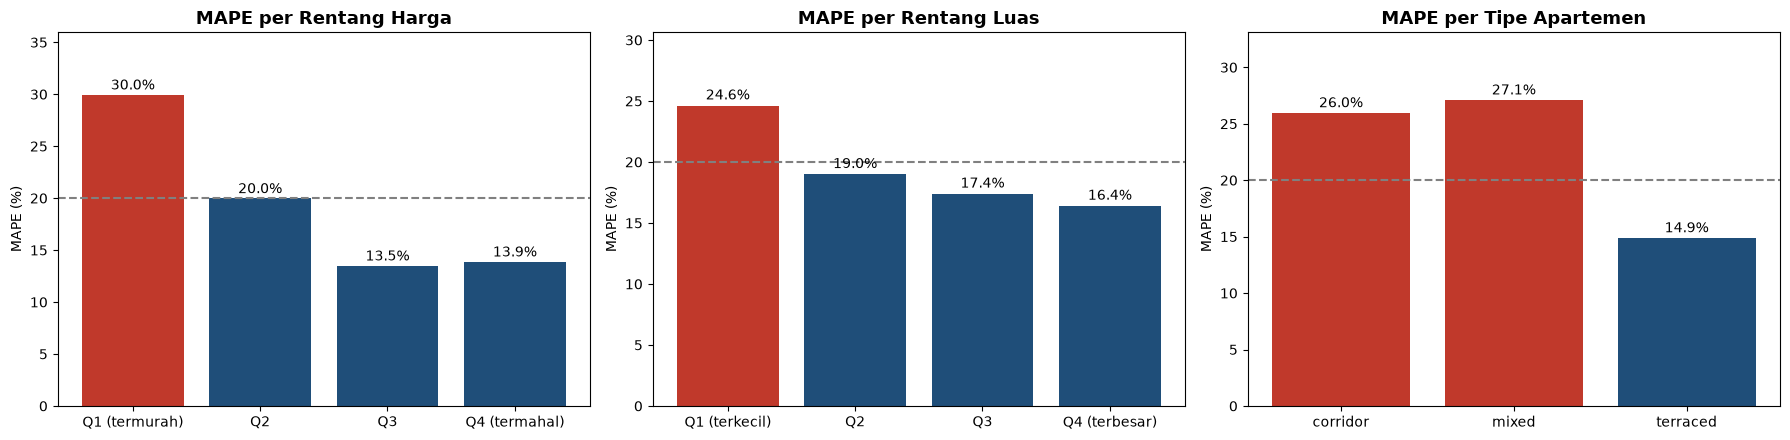

In [75]:
# Grafik MAPE per kelompok unit (merah = di atas target 20%)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
kelompok = [('rentang_harga', 'MAPE per Rentang Harga'), ('rentang_luas', 'MAPE per Rentang Luas'), ('HallwayType', 'MAPE per Tipe Apartemen')]

for ax, (kolom, judul) in zip(axes, kelompok):
    data = hasil_pred.groupby(kolom, observed=True)['ape'].mean() * 100
    ax.bar(data.index.astype(str), data.values, color=['#c0392b' if v > 20 else '#1f4e79' for v in data.values])
    ax.axhline(20, color='gray', linestyle='--')
    for j, v in enumerate(data.values):
        ax.text(j, v + 0.5, f'{v:.1f}%', ha='center')
    ax.set_title(judul, size=13, weight='bold')
    ax.set_ylabel('MAPE (%)')
    ax.set_ylim(0, max(data.values) + 6)
plt.tight_layout();

Dari tabel di atas:
- **Rentang harga:** MAPE paling besar pada unit termurah (Q1: sekitar 30%), sedangkan unit di Q3 dan Q4 jauh lebih akurat (sekitar 13,5-14%). Dalam nilai absolut (MAE), error justru terbesar pada unit termahal (sekitar 51 ribu), tetapi karena harganya tinggi, persentasenya kecil.
- **Luas unit:** semakin kecil unitnya, semakin besar MAPE (kuartil terkecil sekitar 24,6% vs terbesar sekitar 16,4%).
- **Tipe apartemen:** unit *terraced* (jumlah terbanyak) memiliki MAPE sekitar 14,9%, sedangkan *corridor* (sekitar 26,0%) dan *mixed* (sekitar 27,1%) jauh kurang akurat.
- **Stasiun:** MAPE terendah pada Banwoldang (sekitar 12,0%) dan `no_subway_nearby` (sekitar 11,0%), sedangkan Bangoge, Myung-duk, Chil-sung-market, dan Daegu berada di kisaran 24-26%. Perlu hati-hati karena jumlah sampel test pada beberapa stasiun sangat kecil (Daegu hanya 8 unit dan Chil-sung-market 13 unit), sehingga angkanya belum stabil.

**Kesimpulan error analysis:** model **paling dapat dipercaya** untuk unit bertipe *terraced*, berukuran sedang-besar, dan berharga menengah ke atas (MAPE sekitar 12-17%). Model **kurang dapat dipercaya** untuk unit murah dan kecil, serta bertipe *corridor* atau *mixed* (MAPE bisa mencapai 25-30%). Salah satu penyebabnya, harga unit murah memiliki penyebut yang kecil sehingga selisih beberapa puluh ribu saja sudah terlihat besar secara persentase.

**Feature Importances**

Untuk mengetahui fitur apa yang paling memengaruhi harga, menggunakan *permutation importance*: nilai satu fitur diacak, lalu dilihat seberapa besar performa model memburuk. Metode ini bekerja pada fitur asli (sebelum one-hot encoding) sehingga lebih mudah diinterpretasi.

Size(sqf)                           34444.0
YearBuilt                           13897.0
HallwayType                          8650.0
N_FacilitiesInApt                    2610.0
N_Parkinglot(Basement)               2590.0
N_FacilitiesNearBy(ETC)               438.0
TimeToSubway                          374.0
N_SchoolNearBy(University)            182.0
N_FacilitiesNearBy(PublicOffice)       73.0
SubwayStation                          -5.0
dtype: float64


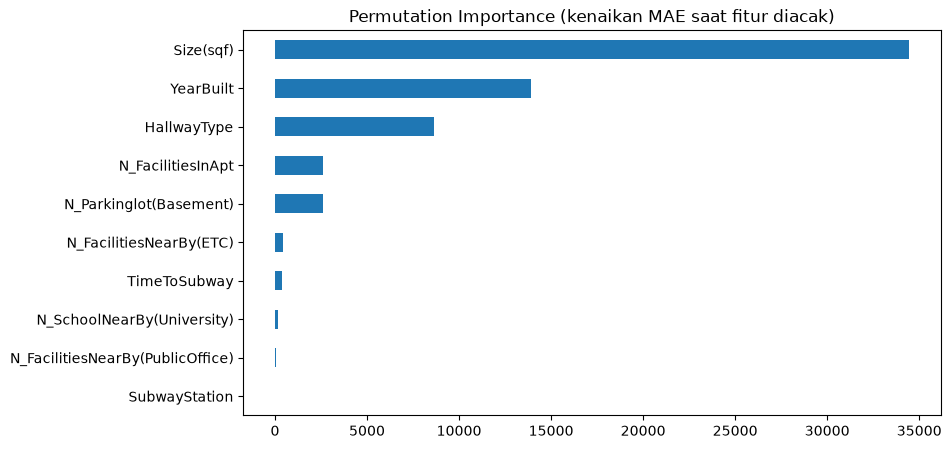

In [76]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=1,
                              scoring='neg_mean_absolute_error')
feature_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

feature_imp.plot(kind='barh', figsize=(9, 5), title='Permutation Importance (kenaikan MAE saat fitur diacak)')
print(feature_imp.sort_values(ascending=False).round(0))

Fitur yang paling berpengaruh adalah **luas unit (`Size(sqf)`)**, diikuti **`YearBuilt`** dan **`HallwayType`**. `N_FacilitiesInApt` dan `N_Parkinglot(Basement)` berpengaruh lebih kecil. Fitur lokasi (`SubwayStation`, `TimeToSubway`) dan jumlah fasilitas/kampus sekitar hampir tidak berkontribusi (importance mendekati 0, bahkan sedikit negatif untuk `SubwayStation`), padahal pada EDA stasiun terlihat berkaitan dengan harga.

Kemungkinan penjelasannya, informasi lokasi sudah 'terwakili' oleh fitur lain: kombinasi `YearBuilt`, `N_Parkinglot(Basement)`, dan karakteristik lain bisa berfungsi seperti 'identitas' kompleks apartemen, sehingga stasiun terdekat menjadi redundan. Perlu diingat juga bahwa permutation importance dapat meremehkan fitur yang saling berkorelasi, jadi hasil ini sebaiknya dibaca bersama eksperimen *feature selection check* di atas.

### **Conclusion**

Berdasarkan pemodelan yang sudah dilakukan:

- **Model final** adalah Gradient Boosting Regressor hasil hyperparameter tuning, dalam satu pipeline bersama preprocessing. Pada test set (541 unit) diperoleh **MAPE sekitar 19,4%, MAE sekitar 38 ribu, RMSE sekitar 46,8 ribu, dan R² sekitar 0,80** (dalam satuan harga pada dataset). Artinya, rata-rata prediksi meleset sekitar 19% dari harga sebenarnya, dan model menjelaskan sekitar 80% variasi harga.
- **Target tercapai, tetapi tipis.** Target MAPE di bawah 20% terpenuhi (19,4%), namun marginnya kecil. Berdasarkan skala Lewis (1982), model berada di batas atas kategori *good forecasting* (10-20%), sehingga sebaiknya dipandang sebagai **rekomendasi harga awal**, bukan harga pasti.
- **Algoritma bukan faktor pembatas.** Decision Tree, Random Forest, dan Gradient Boosting memberi hasil hampir sama, dan tuning hampir tidak mengubah skor. Batas akurasi lebih ditentukan oleh informasi pada fitur yang tersedia.
- **Fitur paling berpengaruh:** luas unit, tahun bangun, dan tipe apartemen. Fitur lokasi dan jumlah fasilitas sekitar tampak redundan pada data ini.
- **Dampak bisnis (ilustratif):** dibanding aturan sederhana harga per sqft x luas (MAPE sekitar 32%), model menurunkan MAPE menjadi sekitar 19% dan memangkas rata-rata kerugian akibat underpricing dari sekitar 11,8% menjadi sekitar 7,2% dari harga unit. Perkiraan nilai rupiahnya dijelaskan pada bagian *Estimasi Dampak Bisnis*.
- **Model dapat dipercaya** untuk unit bertipe *terraced*, berukuran sedang-besar, dan berharga menengah ke atas (MAPE sekitar 12-17%).
- **Model kurang dapat dipercaya** untuk unit murah dan kecil serta bertipe *corridor* atau *mixed* (MAPE bisa 25-30%), dan untuk unit di luar rentang data training (harga 32.743-585.840), di mana unit termahal cenderung diremehkan.

**Batasan project:**
- **Data:** hanya 2.701 baris setelah duplikat dibuang, hanya dari kota Daegu, tanpa informasi waktu transaksi, lantai, kondisi unit, atau koordinat lokasi.
- **Validasi:** pembagian train-test dilakukan acak, sehingga unit dari kompleks apartemen yang sama bisa berada di train dan test. Performa pada **kompleks yang benar-benar baru** kemungkinan lebih rendah dari angka di atas. Data tidak memiliki ID kompleks untuk mengujinya.
- **Model:** tidak bisa mengekstrapolasi di luar rentang harga training.

### **Business Recommendations**

- **Smart Pricing Assistant & Fair Price Badge:** Integrasikan rekomendasi harga ML ke dasbor penjual dan beri *badge* **"Fair Price"** pada unit yang harganya sesuai pasar agar pembeli lebih tertarik.

- **Insentif Adopsi (Komisi Berjenjang):** Berikan potongan biaya/komisi platform bagi pemilik apartemen yang menyetujui rekomendasi harga model untuk mempercepat adopsi fitur.

- **Monetisasi & Optimasi Fitur Kunci:** Optimalkan unit berdasarkan variabel paling berpengaruh (`Size`, `HallwayType`, `YearBuilt`) melalui tawaran paket renovasi/staging untuk unit lama.

- **Uji Coba & Monitor KPI Bisnis:** Jalankan *A/B Testing* dan ukur tingkat adopsi fitur (*Adoption Rate*), kecepatan transaksi (*Days on Market*), serta total volume transaksi (*GTV*).

### **Estimasi Dampak Bisnis**

Bagian ini menerjemahkan akurasi model menjadi **perkiraan nilai rupiah**. Angkanya bersifat **ilustratif, bukan angka riil**, karena bergantung pada asumsi yang dijelaskan di bawah dan harus dibuktikan lewat uji coba nyata (A/B testing).

**Logika perhitungan:**
- **Underpricing** (harga listing di bawah harga pasar): selisihnya adalah uang yang hilang bagi penjual. Ini adalah *kerugian yang ingin diminimalkan*.
- **Overpricing** (harga listing di atas harga pasar): unit lebih lama terjual, sehingga ada biaya menunggu (modal tertahan, biaya kepemilikan unit).
- **Pembanding (tanpa model):** cara penjual menaksir harga dimodelkan dengan aturan sederhana, yaitu *harga per sqft (median) x luas unit*. Ini hanya perkiraan kasar dari praktik penjual; kualitas taksiran penjual sebenarnya bisa lebih baik atau lebih buruk.
- Seluruh error dihitung dalam **persentase terhadap harga pasar** (harga aktual), sehingga tidak bergantung pada satuan harga di dataset dan dapat diterapkan ke rupiah.

In [77]:
# Pembanding: cara penjual menaksir harga tanpa model = harga per sqft (median data train) x luas unit
harga_per_sqf = (y_train / X_train['Size(sqf)']).median()
pred_baseline = X_test['Size(sqf)'] * harga_per_sqf

def profil_kesalahan(pred):
    # selisih relatif terhadap harga pasar (harga aktual): positif = overpricing, negatif = underpricing
    selisih = (pred - y_test) / y_test
    return pd.Series({
        'MAPE': selisih.abs().mean(),
        'Rata-rata underpricing (% harga)': (-selisih).clip(lower=0).mean(),
        'Rata-rata overpricing (% harga)': selisih.clip(lower=0).mean(),
        '% listing underpricing > 20%': (selisih < -0.2).mean(),
        '% listing overpricing > 20%': (selisih > 0.2).mean(),
        'Bias rata-rata (+ = cenderung di atas pasar)': selisih.mean()
    })

dampak = pd.DataFrame({
    'Tanpa model (harga/sqft x luas)': profil_kesalahan(pred_baseline),
    'Dengan model ML': profil_kesalahan(y_pred)
}).T
dampak.round(3)

,MAPE,Rata-rata underpricing (% harga),Rata-rata overpricing (% harga),% listing underpricing > 20%,% listing overpricing > 20%,Bias rata-rata (+ = cenderung di atas pasar)
Tanpa model (harga/sqft x luas),0.321,0.118,0.203,0.283,0.299,0.085
Dengan model ML,0.194,0.072,0.122,0.172,0.266,0.049


Pada test set (541 unit):
- **MAPE** turun dari sekitar 32% (aturan harga per sqft) menjadi sekitar 19% dengan model.
- **Rata-rata underpricing** (uang yang hilang karena harga di bawah pasar) turun dari sekitar 11,8% menjadi sekitar 7,2% dari harga unit, atau berkurang sekitar 39%. Listing yang underpricing lebih dari 20% turun dari sekitar 28% menjadi sekitar 17%.
- **Rata-rata overpricing** turun dari sekitar 20,3% menjadi sekitar 12,2%. Namun proporsi listing yang overpricing lebih dari 20% hanya turun dari sekitar 29,9% menjadi sekitar 26,6%, sehingga perbaikan untuk overpricing ekstrem lebih kecil dibanding perbaikan untuk underpricing.
- **Bias rata-rata** model bernilai positif (sekitar +5%), artinya model cenderung sedikit memprediksi di atas harga aktual. Bias pembanding lebih besar (sekitar +8,5%).

**Business Outcome Evaluation: Confusion Matrix Tier Harga**

Pada klasifikasi, confusion matrix membandingkan kelas aktual dan prediksi. Pada regresi bisa membuat padanannya dengan mengelompokkan harga ke tiga **tier** (Murah, Menengah, Mahal, berdasarkan sepertiga data train), lalu melihat apakah unit 'masuk' ke tier yang benar. Sel di **bawah diagonal** adalah unit yang prediksinya jatuh ke tier lebih rendah dari aktual (*underpricing*), sedangkan sel di **atas diagonal** adalah unit yang prediksinya lebih tinggi dari aktual (*overpricing*).

Tanpa model: tepat=337, underpricing (di bawah diagonal)=118, overpricing (di atas diagonal)=86
Dengan model: tepat=406, underpricing (di bawah diagonal)=71, overpricing (di atas diagonal)=64


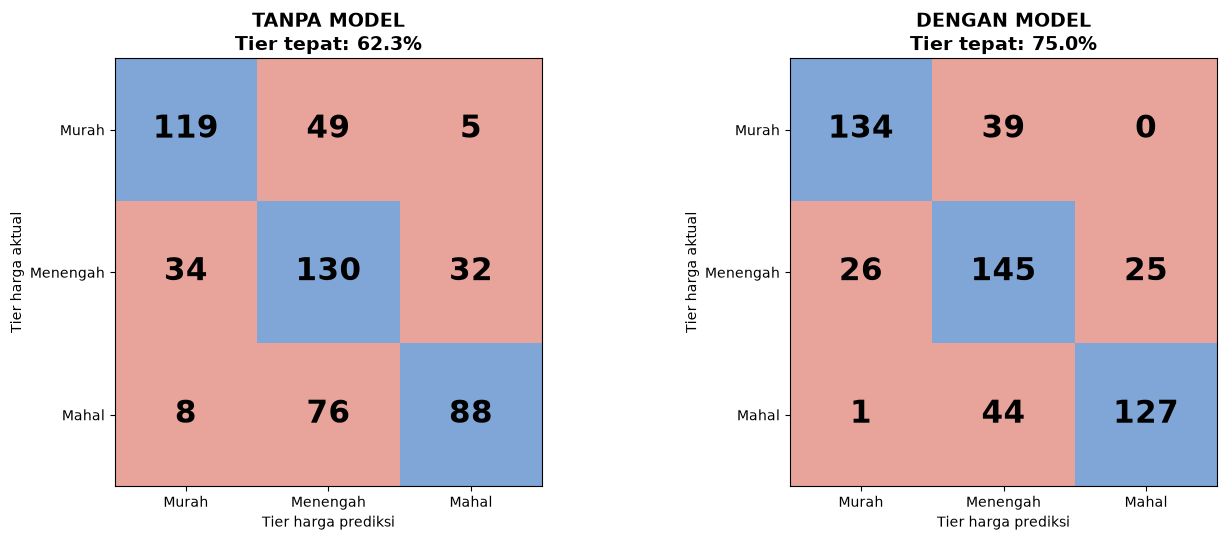

In [78]:
from sklearn.metrics import confusion_matrix
from matplotlib.colors import ListedColormap

# Tier harga berdasarkan sepertiga dan duapertiga data train
batas_tier = y_train.quantile([1/3, 2/3]).values
label_tier = ['Murah', 'Menengah', 'Mahal']

def ke_tier(harga):
    return pd.cut(pd.Series(np.asarray(harga)), bins=[-np.inf, batas_tier[0], batas_tier[1], np.inf], labels=label_tier).astype(str)

tier_aktual = ke_tier(y_test)
cm_tanpa = confusion_matrix(tier_aktual, ke_tier(pred_baseline), labels=label_tier)
cm_model = confusion_matrix(tier_aktual, ke_tier(y_pred), labels=label_tier)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, cm, judul in zip(axes, [cm_tanpa, cm_model], ['TANPA MODEL', 'DENGAN MODEL']):
    ax.imshow(np.eye(3), cmap=ListedColormap(['#e8a39b', '#7fa6d6']))   # diagonal = benar (biru), lainnya = salah (merah)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=22, weight='bold')
    ax.set_xticks(range(3)); ax.set_xticklabels(label_tier)
    ax.set_yticks(range(3)); ax.set_yticklabels(label_tier)
    ax.set_xlabel('Tier harga prediksi'); ax.set_ylabel('Tier harga aktual')
    ax.set_title(f'{judul}\nTier tepat: {np.trace(cm)/cm.sum():.1%}', size=14, weight='bold')
plt.tight_layout()

for nama, cm in [('Tanpa model', cm_tanpa), ('Dengan model', cm_model)]:
    print(f'{nama}: tepat={np.trace(cm)}, underpricing (di bawah diagonal)={np.tril(cm, -1).sum()}, overpricing (di atas diagonal)={np.triu(cm, 1).sum()}')

Pada test set (541 unit):
- Unit yang masuk ke **tier harga yang tepat** naik dari 337 (62,3%) menjadi 406 (75,0%).
- Unit **underpricing** (prediksi jatuh ke tier lebih rendah dari aktual) turun dari 118 menjadi 71, atau sekitar 40%. Unit **overpricing** turun dari 86 menjadi 64, atau sekitar 26%.
- Seperti pada analisis sebelumnya, perbaikan untuk underpricing lebih besar dibanding overpricing.

**Simulasi nilai rupiah**

Parameter di bawah adalah **asumsi** yang bisa diubah sesuai kondisi nyata platform.

In [ ]:
harga_rata2_unit = 1000000000          
listing_per_tahun = 1000               
biaya_tunggu_per_bulan = 0.005         
bulan_tunggu_tambahan = 3              
skenario_adopsi = {'Konservatif': 0.30, 'Moderat': 0.60, 'Optimistis': 0.90}  


under_tanpa = dampak.loc['Tanpa model (harga/sqft x luas)', 'Rata-rata underpricing (% harga)']
under_model = dampak.loc['Dengan model ML', 'Rata-rata underpricing (% harga)']
over20_tanpa = dampak.loc['Tanpa model (harga/sqft x luas)', '% listing overpricing > 20%']
over20_model = dampak.loc['Dengan model ML', '% listing overpricing > 20%']

def rupiah(x):
    teks = f'Rp {x/1e9:.1f} miliar' if abs(x) >= 1e9 else f'Rp {x/1e6:.1f} juta'
    return teks.replace('.', ',')

# Per satu listing
hemat_under_per_listing = (under_tanpa - under_model) * harga_rata2_unit
persen_hemat = f'{(under_tanpa - under_model)*100:.1f}'.replace('.', ',')
print(f'Kerugian underpricing yang dapat dihindari per listing: {rupiah(hemat_under_per_listing)} '
      f'({persen_hemat}% dari harga unit)')

# Per tahun, untuk tiga skenario adopsi
baris = []
for nama, adopsi in skenario_adopsi.items():
    n_listing = listing_per_tahun * adopsi
    hemat_under = (under_tanpa - under_model) * harga_rata2_unit * n_listing
    hemat_over = (over20_tanpa - over20_model) * n_listing * harga_rata2_unit * biaya_tunggu_per_bulan * bulan_tunggu_tambahan
    baris.append({
        'Skenario': nama,
        'Listing memakai model': int(n_listing),
        'Underpricing yang dihindari': rupiah(hemat_under),
        'Biaya tunggu overpricing yang dihemat': rupiah(hemat_over),
        'Total perkiraan manfaat / tahun': rupiah(hemat_under + hemat_over)
    })

pd.DataFrame(baris).set_index('Skenario')

Kerugian underpricing yang dapat dihindari per listing: Rp 45,7 juta (4,6% dari harga unit)


,Listing memakai model,Underpricing yang dihindari,Biaya tunggu overpricing yang dihemat,Total perkiraan manfaat / tahun
Skenario,,,,
Konservatif,300,"Rp 13,7 miliar","Rp 149,7 juta","Rp 13,8 miliar"
Moderat,600,"Rp 27,4 miliar","Rp 299,4 juta","Rp 27,7 miliar"
Optimistis,900,"Rp 41,1 miliar","Rp 449,2 juta","Rp 41,5 miliar"


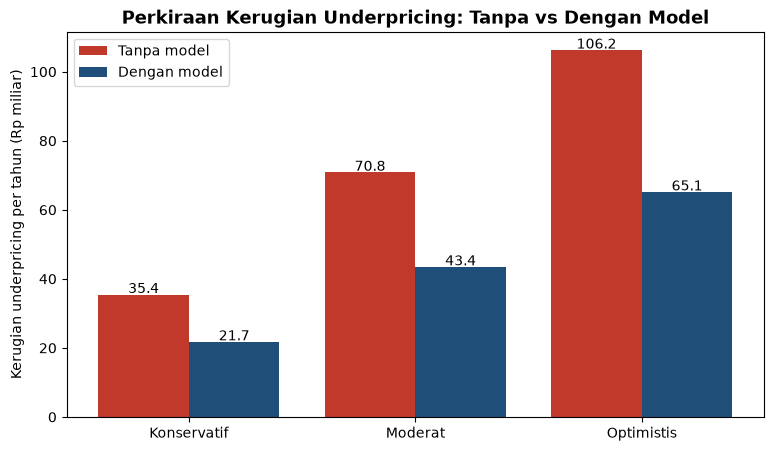

In [80]:
# Perbandingan kerugian underpricing per tahun (Rp miliar): tanpa model vs dengan model, per skenario adopsi
manfaat = {}
for nama, adopsi in skenario_adopsi.items():
    n_listing = listing_per_tahun * adopsi
    manfaat[nama] = (under_tanpa * harga_rata2_unit * n_listing / 1e9, under_model * harga_rata2_unit * n_listing / 1e9)

posisi = np.arange(len(manfaat))
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(posisi - 0.2, [v[0] for v in manfaat.values()], width=0.4, color='#c0392b', label='Tanpa model')
ax.bar(posisi + 0.2, [v[1] for v in manfaat.values()], width=0.4, color='#1f4e79', label='Dengan model')
for p, (a, b) in zip(posisi, manfaat.values()):
    ax.text(p - 0.2, a + 0.5, f'{a:.1f}', ha='center')
    ax.text(p + 0.2, b + 0.5, f'{b:.1f}', ha='center')
ax.set_xticks(posisi); ax.set_xticklabels(manfaat.keys())
ax.set_ylabel('Kerugian underpricing per tahun (Rp miliar)')
ax.set_title('Perkiraan Kerugian Underpricing: Tanpa vs Dengan Model', size=13, weight='bold')
ax.legend();

**Hasil:**
- Dengan asumsi harga rata-rata unit Rp 1 miliar, model dapat menghindarkan kerugian underpricing sekitar **Rp 45,7 juta per listing** (4,6% dari harga unit).
- Pada skala 1.000 listing per tahun, perkiraan total manfaat sekitar **Rp 13,8 miliar** (konservatif, 30% penjual memakai model), **Rp 27,7 miliar** (moderat, 60%), dan **Rp 41,5 miliar** (optimistis, 90%) per tahun.
- Hampir seluruh manfaat berasal dari **berkurangnya underpricing** (Rp 13,7-41,1 miliar), sedangkan penghematan biaya tunggu akibat overpricing jauh lebih kecil (sekitar Rp 150-450 juta) karena model tidak banyak mengurangi proporsi listing yang overpricing ekstrem.


#### **Save Model**

Pipeline final (preprocessing + model terbaik hasil tuning) disimpan menggunakan Pickle, lalu dimuat kembali untuk memastikan hasilnya sama dengan yang dievaluasi di atas.

In [81]:
import pickle

# Simpan pipeline final (preprocessing + Gradient Boosting hasil tuning)
filename = 'Model_Daegu_Apartment_GB.sav'
pickle.dump(final_model, open(filename, 'wb'))

In [82]:
# Load kembali model dan pastikan hasilnya identik
loaded_model = pickle.load(open(filename, 'rb'))
print('MAPE test (model yang dimuat):', round(mean_absolute_percentage_error(y_test, loaded_model.predict(X_test)), 4))
print('MAPE test (model sebelumnya) :', round(mean_absolute_percentage_error(y_test, y_pred), 4))

MAPE test (model yang dimuat): 0.1942
MAPE test (model sebelumnya) : 0.1942


In [83]:
# Contoh penggunaan: memprediksi harga satu unit apartemen baru
unit_baru = pd.DataFrame([{
    'HallwayType': 'terraced',
    'TimeToSubway': '0-5min',
    'SubwayStation': 'Myung-duk',
    'N_FacilitiesNearBy(ETC)': 0.0,
    'N_FacilitiesNearBy(PublicOffice)': 3.0,
    'N_SchoolNearBy(University)': 2.0,
    'N_Parkinglot(Basement)': 600.0,
    'YearBuilt': 2007,
    'N_FacilitiesInApt': 5,
    'Size(sqf)': 900
}])

print(f"Perkiraan harga: {loaded_model.predict(unit_baru)[0]:,.0f} Won")

Perkiraan harga: 262,785 Won
